# 02 · Manifold — scFates principal tree
Fit a principal tree to the cell-state manifold, root it at the basal progenitor hub (developmental origin; Gast/pSom present, differentiation/EMT markers low), and compute pseudotime.

The embedding shows a **hub-and-spoke** topology — a basal progenitor core diverging into a keratinocyte-differentiation arm and a TSK / leading-edge arm — so a branching **tree** is the correct geometry (not a curve).

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np
import scanpy as sc
import scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1

In [2]:
name = os.path.split(os.getcwd())[1]
cat  = os.path.split(os.path.split(os.getcwd())[0])[1]
pth  = os.path.join(*(['..']*4))
pth_in  = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_out = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)

In [3]:
# load processed data from h5ad file
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad')); adata

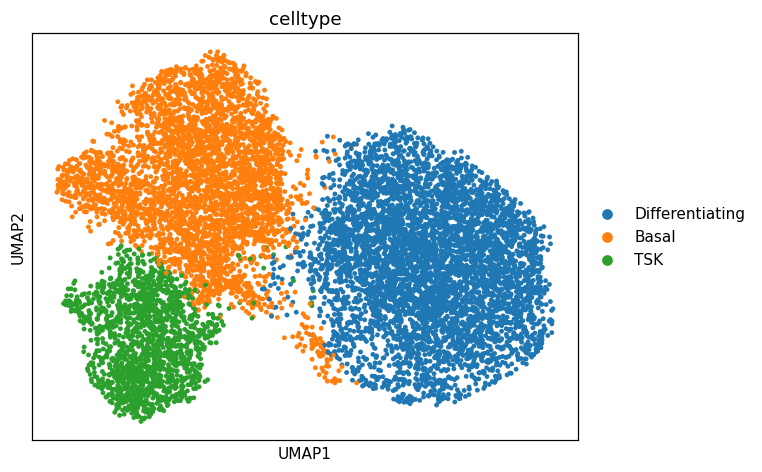

In [4]:
# visual inspection — loaded data
sc.pl.umap(adata, color = 'celltype', size = 40)

### Fit principal tree
`Nodes=80, ppt_lambda=600, ppt_sigma=0.4` — chosen so the tree is smooth enough to suppress UMAP-density noise yet resolves the primary bifurcation. (Puram's 200 nodes over 2.4k cells would over-fit here; the count is re-derived for this manifold.) The fit is stable across the surrounding parameter range: one central hub with a differentiation arm and a TSK arm.

inferring a principal tree --> parameters used 
    80 principal points, sigma = 0.4, lambda = 600, metric = euclidean
    fitting:  18%|#8        | 9/50 [00:01<00:05,  7.49it/s]
    converged
    finished (0:00:01) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.


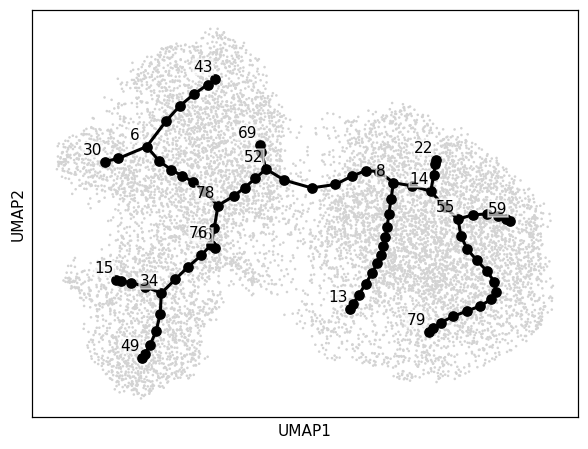

In [5]:
scf.tl.tree(adata, method = 'ppt', Nodes = 80,
            ppt_lambda = 600, ppt_sigma = 0.4,
            use_rep = 'X_umap', seed = 1,
            plot = True, basis = 'umap')

### Root at the basal progenitor hub
Score each principal node by its cells' basal-progenitor identity (KRT14/KRT5/TP63/COL17A1) and root at the basal node that sits at the branch point. This is the developmental origin — Crest (neural crest) is a *late* program and must not be used as the root (the evaluation-audit rule).

In [6]:
R = adata.obsm['X_R']                       # soft cell->node assignment
basal = adata[:, ['KRT14','KRT5','TP63','COL17A1']].X.toarray().mean(1)
node_basal = (R * basal[:, None]).sum(0) / R.sum(0)
B = adata.uns['graph']['B']; deg = np.asarray(B.sum(1)).ravel()
forks = np.where(deg > 2)[0]
root = int(forks[np.argmax(node_basal[forks])])
print('fork nodes:', forks.tolist())
print('root (basal-max fork):', root, '| basal score', round(float(node_basal[root]), 2))
scf.tl.root(adata, root)

fork nodes: [6, 8, 14, 34, 52, 55, 76, 78]
root (basal-max fork): 76 | basal score 3.24
node 76 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.


In [7]:
# infer cell-state gradients
scf.tl.pseudotime(adata, seed = 1)

projecting cells onto the principal graph
    finished (0:00:06) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.


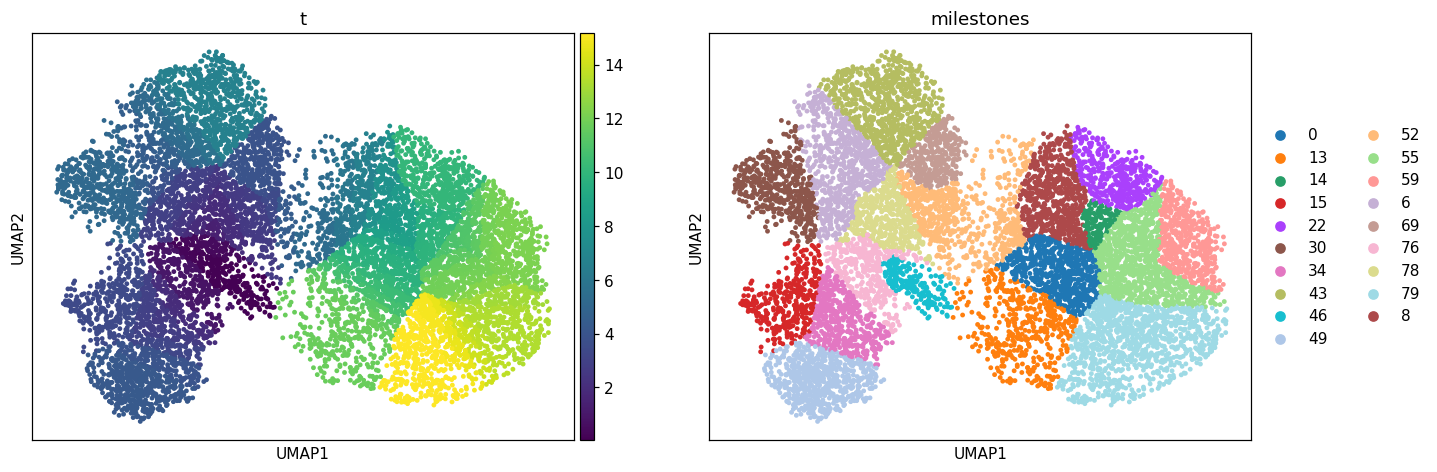

In [8]:
# visual inspection — manifold / gradients
sc.pl.umap(adata, color = ['t', 'milestones'], size = 40)

Pseudotime radiates smoothly from the hub with no fold-back; the tree edges (drawn above) trace the cloud cleanly. Rename the milestones by biological role.

            _diff  _tsk      t
milestones                    
0            1.02  0.04   9.95
13           1.16  0.10  11.62
14           1.54  0.03   9.24
15           0.54  0.35   3.44
22           1.94  0.02  10.07
30           0.47  0.11   5.12
34           0.58  0.36   2.67
43           0.50  0.10   6.46
46           0.72  0.11   0.05
49           0.64  0.93   4.16
52           0.66  0.09   4.05
55           2.02  0.03  11.51
59           2.77  0.03  12.10
6            0.48  0.11   4.15
69           0.60  0.07   3.93
76           0.62  0.17   0.66
78           0.62  0.09   1.94
79           2.14  0.09  14.37
8            1.07  0.04   7.49
rename: {'76': 'Basal_hub', '59': 'Differentiated', '49': 'TSK'}


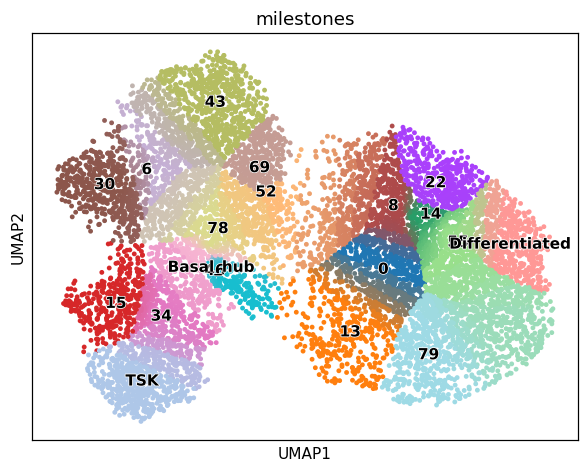

In [9]:
# rename milestones -> hub / arm tips (by module + marker identity)
import pandas as pd
ms = adata.obs.groupby('milestones', observed = True)
diff_sc = adata[:, ['KRT1','KRT10','SPRR1B']].X.toarray().mean(1)
tsk_sc  = adata[:, ['MMP10','MMP1','LAMC2','PTHLH']].X.toarray().mean(1)
adata.obs['_diff'] = diff_sc; adata.obs['_tsk'] = tsk_sc
tab = adata.obs.groupby('milestones', observed = True)[['_diff','_tsk','t']].mean()
print(tab.round(2))
root_ms = adata.obs.loc[adata.obs.t == adata.obs.t.min(), 'milestones'].iloc[0]
diff_tip = tab['_diff'].idxmax(); tsk_tip = tab['_tsk'].idxmax()
rename = {str(root_ms): 'Basal_hub', str(diff_tip): 'Differentiated', str(tsk_tip): 'TSK'}
print('rename:', rename)
adata.obs = adata.obs.drop(columns = ['_diff','_tsk'])
scf.tl.rename_milestones(adata, new = rename)
scf.pl.milestones(adata, basis = 'umap', annotate = True, s = 40)

In [10]:
# save manifold to h5ad file
adata.write(os.path.join(pth_in, 'manifold.h5ad'))

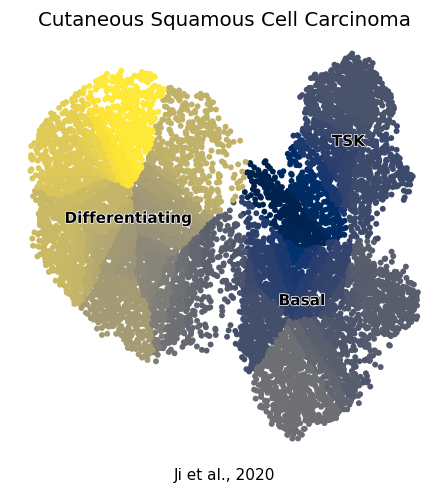

In [11]:
# save manifold embedding figure
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 't', cmap = 'cividis', size = 60,
           colorbar_loc = None, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'celltype', size = 60, alpha = 0,
           legend_loc = 'on data', legend_fontoutline = 1,
           frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Cutaneous Squamous Cell Carcinoma', size = 13)
ax.text(.5, -.05, 'Ji et al., 2020', ha = 'center', transform = ax.transAxes)
fig.savefig(os.path.join(pth_out, 'manifold.pdf'), bbox_inches = 'tight')